# Real Madrid AI Transfer Intelligence
## Notebook 05 — ML Player Archetypes & Similarity

**Objective:** use unsupervised machine learning to identify statistical player archetypes within the Real Madrid squad and find players with similar statistical profiles. This is an exploratory scouting-support component, not a model that predicts transfer success.

**Input:** `data/processed/real_madrid_player_ratings.csv` from Notebook 04 (preferred), or `data/processed/real_madrid_player_season_clean.csv` from Notebook 02 as fallback.

**Why clustering instead of supervised prediction?** The current dataset contains only three seasons of one club. It does not provide a sufficiently large, representative labelled sample of transfer outcomes or future performance. Training a supervised transfer-success model here would be misleading. Clustering can be used as an exploratory method, provided sample size and feature coverage are reported.

**Guardrails**
- Cluster players only within broad position groups (FW/MF/DF); do not compare goalkeepers with outfield players.
- Use available numeric per-90 metrics, not player names, IDs, season labels or target-like outcome labels.
- Impute missing feature values with the median only for the clustering matrix; report the missingness and retain the original data unchanged.
- Standardize features before K-Means.
- Select cluster count using silhouette score where sample size permits; compare against a simple baseline of one cluster (no segmentation).
- Treat clusters as statistical profiles, not quality grades.


## 1. Load the best available dataset

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import Pipeline

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = PROJECT_ROOT / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
for folder in [REPORTS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

RATING_PATH = DATA_DIR / "real_madrid_player_ratings.csv"
CLEAN_PATH = DATA_DIR / "real_madrid_player_season_clean.csv"

if RATING_PATH.exists():
    INPUT_PATH = RATING_PATH
elif CLEAN_PATH.exists():
    INPUT_PATH = CLEAN_PATH
else:
    raise FileNotFoundError(
        "Could not find player_ratings.csv or player_season_clean.csv. "
        "Run Notebook 02 and preferably Notebook 04 first."
    )

df = pd.read_csv(INPUT_PATH)
print("Input:", INPUT_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


,league,season,team,player_name,nation,pos,age,born,playing_time_mp,playing_time_starts,...,starts,goals,player_id,club,goals_per_90,position_group,performance_score,metrics_used,position_metrics_available,sample_flag
0,ESP-La Liga,2324,Real Madrid,Andriy Lunin,UKR,GK,24,1999,21,21,...,21,0,andriy_lunin,Real Madrid,0.000000,GK,NaN,NaN,NaN,Sufficient sample (>=450)
1,ESP-La Liga,2324,Real Madrid,Antonio Rüdiger,GER,DF,30,1993,33,30,...,30,1,antonio_rudiger,Real Madrid,0.033223,DF,NaN,NaN,NaN,Sufficient sample (>=450)
2,ESP-La Liga,2324,Real Madrid,Arda Güler,TUR,"MF,FW",18,2005,10,4,...,4,6,arda_guler,Real Madrid,1.432361,FW,100.0,1.0,1.0,Limited sample (<450)
3,ESP-La Liga,2324,Real Madrid,Aurélien Tchouaméni,FRA,"MF,DF",23,2000,27,22,...,22,3,aurelien_tchouameni,Real Madrid,0.135883,MF,100.0,1.0,1.0,Sufficient sample (>=450)
4,ESP-La Liga,2324,Real Madrid,Brahim Díaz,MAR,"MF,FW",23,1999,31,18,...,18,8,brahim_diaz,Real Madrid,0.466019,FW,50.0,1.0,1.0,Sufficient sample (>=450)


## 2. Standardize fields and identify position groups

In [2]:
def first_existing(options):
    return next((c for c in options if c in df.columns), None)

player_col = first_existing(["player_name", "player"])
season_col = first_existing(["season"])
position_col = first_existing(["position_group", "position", "pos"])
minutes_col = first_existing(["minutes", "min", "playing_time_min"])

if player_col is None or season_col is None or position_col is None:
    raise ValueError(
        "Required player, season or position field is missing. "
        f"Available columns: {df.columns.tolist()}"
    )

df = df.copy()
df["player_name"] = df[player_col].astype("string").str.strip()
df["season"] = df[season_col].astype("string").str.strip()

def broad_position(value):
    if pd.isna(value):
        return "Unknown"
    value = str(value).upper()
    if value in {"GK", "FW", "MF", "DF"}:
        return value
    tokens = [x.strip() for x in value.replace("/", ",").replace(";", ",").split(",")]
    if "GK" in tokens: return "GK"
    if "FW" in tokens: return "FW"
    if "MF" in tokens: return "MF"
    if "DF" in tokens: return "DF"
    return "Unknown"

df["position_group"] = df[position_col].map(broad_position)
df["minutes"] = pd.to_numeric(df[minutes_col], errors="coerce") if minutes_col else np.nan

# A player may have one row per season. Keep player-season as the analysis unit.
if df.duplicated(["player_name", "season"]).any():
    print("Warning: duplicate player-season rows found. Inspect before clustering.")
    display(df.loc[df.duplicated(["player_name", "season"], keep=False)].sort_values(["player_name", "season"]).head(30))

display(df.groupby(["season", "position_group"]).agg(
    player_season_rows=("player_name", "size"),
    unique_players=("player_name", "nunique"),
    median_minutes=("minutes", "median")
).reset_index())


,season,position_group,player_season_rows,unique_players,median_minutes
0,2324,DF,8,8,1569.5
1,2324,FW,8,8,1616.0
2,2324,GK,3,3,1198.0
3,2324,MF,8,8,1752.5
4,2425,DF,11,11,938.0
5,2425,FW,7,7,1385.0
6,2425,GK,3,3,630.0
7,2425,MF,9,9,1215.0
8,2526,DF,13,13,977.0
9,2526,FW,8,8,1000.5


## 3. Select available numeric features

In [4]:
print("ALL COLUMNS:")
for col in df.columns:
    print(col)

print("\nPOTENTIAL PERFORMANCE METRICS:")
for col in df.columns:
    if any(word in col.lower() for word in [
        "goal", "assist", "xg", "xa", "shot",
        "pass", "carry", "tackle", "interception",
        "minute", "playing"
    ]):
        print(col, "| non-null:", df[col].notna().sum())

ALL COLUMNS:
league
season
team
player_name
nation
pos
age
born
playing_time_mp
playing_time_starts
playing_time_min
playing_time_90s
performance_gls
performance_ast
performance_g_a
performance_g_pk
performance_pk
performance_pkatt
performance_crdy
performance_crdr
per_90_minutes_gls
per_90_minutes_ast
per_90_minutes_g_a
per_90_minutes_g_pk
per_90_minutes_g_a_pk
90s
standard_gls
standard_sh
standard_sot
standard_sh_90
standard_sot_90
standard_g_sh
standard_g_sot
standard_pk
standard_pkatt
playing_time_mn_mp
starts_starts
starts_mn_start
starts_compl
subs_subs
subs_mn_sub
subs_unsub
team_success_ppm
team_success_ong
team_success_onga
team_success
team_success_90
team_success_on_off
performance_2crdy
performance_fls
performance_fld
performance_off
performance_crs
performance_int
performance_tklw
performance_pkwon
performance_pkcon
performance_og
performance_ga
performance_ga90
performance_sota
performance_saves
performance_save
performance_w
performance_d
performance_l
performance_cs
pen

In [5]:
# Check whether source columns exist
possible_columns = [
    "goals", "assists",
    "standard_gls", "standard_ast",
    "minutes", "playing_time_min"
]

for col in possible_columns:
    if col in df.columns:
        print(
            col,
            "| non-null:", df[col].notna().sum(),
            "| dtype:", df[col].dtype
        )

goals | non-null: 92 | dtype: int64
standard_gls | non-null: 92 | dtype: int64
minutes | non-null: 92 | dtype: float64
playing_time_min | non-null: 92 | dtype: float64


In [6]:
# 1. Map source columns to standardized metric names

METRIC_MAPPING = {
    "goals_per_90": "per_90_minutes_gls",
    "assists_per_90": "per_90_minutes_ast",
    "goal_contributions_per_90": "per_90_minutes_g_a",
    "shots_per_90": "standard_sh_90",
    "shots_on_target_per_90": "standard_sot_90",
}

# Copy existing source metrics
for new_col, source_col in METRIC_MAPPING.items():
    if source_col in df.columns:
        df[new_col] = pd.to_numeric(
            df[source_col], errors="coerce"
        )

# 2. Calculate additional per-90 metrics from event totals

minutes = pd.to_numeric(
    df["minutes"], errors="coerce"
)

def calculate_per_90(source_col, target_col):
    if source_col in df.columns:
        values = pd.to_numeric(
            df[source_col], errors="coerce"
        )

        df[target_col] = np.where(
            minutes > 0,
            values * 90 / minutes,
            np.nan
        )

calculate_per_90(
    "performance_tklw",
    "tackles_won_per_90"
)

calculate_per_90(
    "performance_int",
    "interceptions_per_90"
)

calculate_per_90(
    "performance_crs",
    "crosses_per_90"
)

# 3. Select available features
FEATURE_CANDIDATES = [
    "goals_per_90",
    "assists_per_90",
    "shots_per_90",
    "shots_on_target_per_90",
    "tackles_won_per_90",
    "interceptions_per_90",
    "crosses_per_90"
]

features = [
    col for col in FEATURE_CANDIDATES
    if col in df.columns
    and df[col].notna().sum() > 0
    and df[col].nunique(dropna=True) > 1
]

# 4. Feature coverage report
feature_coverage = pd.DataFrame([
    {
        "feature": col,
        "non_missing": int(df[col].notna().sum()),
        "missing_percent": round(
            df[col].isna().mean() * 100, 1
        ),
        "unique_values": int(df[col].nunique())
    }
    for col in features
])

print("Available ML features:", features)
display(feature_coverage)

if len(features) < 2:
    raise ValueError(
        f"Not enough features for clustering: {features}"
    )

,feature,non_missing,missing_percent,unique_values
0,goals_per_90,92,0.0,32
1,assists_per_90,92,0.0,30
2,shots_per_90,92,0.0,64
3,shots_on_target_per_90,92,0.0,49
4,tackles_won_per_90,92,0.0,72
5,interceptions_per_90,92,0.0,67
6,crosses_per_90,92,0.0,66


## 4. Build a player-season modelling sample

In [7]:
MIN_MINUTES_FOR_CLUSTERING = 450

model_df = df[
    df["position_group"].isin(["FW", "MF", "DF"])
    & df["minutes"].ge(MIN_MINUTES_FOR_CLUSTERING)
].copy()

# Remove features that have no observed values or no variation in the filtered sample.
usable_features = [
    c for c in features
    if model_df[c].notna().sum() >= 3 and model_df[c].nunique(dropna=True) >= 2
]

print("Rows after position/minutes filter:", len(model_df))
print("Usable features:", usable_features)

if len(usable_features) < 2:
    raise ValueError(
        "Not enough usable features after filtering. "
        "Review available metrics or reduce MIN_MINUTES_FOR_CLUSTERING with a documented reason."
    )

if len(model_df) < 8:
    raise ValueError(
        f"Only {len(model_df)} rows remain. This is too small for meaningful clustering. "
        "Expand the dataset to more clubs/seasons before proceeding."
    )

X_raw = model_df[usable_features].replace([np.inf, -np.inf], np.nan)
display(X_raw.describe().T)


,count,mean,std,min,25%,50%,75%,max
goals_per_90,58.0,0.177931,0.231356,0.000000,0.000000,0.095000,0.212500,0.960000
assists_per_90,58.0,0.155862,0.129588,0.000000,0.050000,0.120000,0.282500,0.430000
shots_per_90,58.0,1.500862,1.181664,0.000000,0.632500,1.060000,2.205000,5.060000
shots_on_target_per_90,58.0,0.586552,0.590924,0.000000,0.150000,0.335000,0.910000,2.630000
tackles_won_per_90,58.0,1.008389,0.498082,0.034629,0.614161,1.007632,1.265625,2.377545
interceptions_per_90,58.0,0.762304,0.462604,0.000000,0.354542,0.783852,1.143430,1.602902
crosses_per_90,58.0,1.642851,1.925160,0.000000,0.214004,0.994106,2.532758,9.750645


## 5. Fit K-Means separately by position

In [8]:
# Evaluate k=2..min(5, n-1), requiring enough rows for each candidate.
# Silhouette is not calculated for a single cluster or when every row becomes its own cluster.
cluster_results = []
clustered_parts = []

for position, group in model_df.groupby("position_group"):
    if len(group) < 8:
        print(f"Skipping {position}: only {len(group)} rows (need >=8 for exploratory clustering).")
        continue

    Xp = group[usable_features].replace([np.inf, -np.inf], np.nan)

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    X_scaled = pipeline.fit_transform(Xp)

    candidate_scores = []
    max_k = min(5, len(group) - 1)

    for k in range(2, max_k + 1):
        km = KMeans(n_clusters=k, random_state=42, n_init=20)
        labels = km.fit_predict(X_scaled)

        if len(np.unique(labels)) < 2 or len(np.unique(labels)) >= len(group):
            continue

        sil = silhouette_score(X_scaled, labels)
        candidate_scores.append((k, sil, km, labels))

    if not candidate_scores:
        print(f"Skipping {position}: no valid silhouette candidate.")
        continue

    best_k, best_silhouette, best_model, best_labels = max(candidate_scores, key=lambda x: x[1])

    part = group.copy()
    part["cluster"] = best_labels.astype(int)
    part["cluster_position"] = position
    clustered_parts.append(part)

    for k, sil, _, _ in candidate_scores:
        cluster_results.append({
            "position_group": position,
            "k": k,
            "silhouette_score": sil,
            "selected": k == best_k,
            "n_rows": len(group)
        })

    print(f"{position}: selected k={best_k}, silhouette={best_silhouette:.3f}, n={len(group)}")

if not clustered_parts:
    raise ValueError(
        "No position group had enough observations for clustering. "
        "Expand the dataset (e.g., add comparable players from other clubs) rather than forcing a model."
    )

clustered = pd.concat(clustered_parts, ignore_index=True)
cluster_evaluation = pd.DataFrame(cluster_results)
display(cluster_evaluation.sort_values(["position_group", "silhouette_score"], ascending=[True, False]))


,position_group,k,silhouette_score,selected,n_rows
1,DF,3,0.265482,True,22
0,DF,2,0.243618,False,22
2,DF,4,0.229105,False,22
3,DF,5,0.190453,False,22
7,FW,5,0.267417,True,16
4,FW,2,0.258010,False,16
6,FW,4,0.246161,False,16
5,FW,3,0.227025,False,16
11,MF,5,0.289193,True,20
8,MF,2,0.281691,False,20


## 6. Compare clusters and describe archetypes

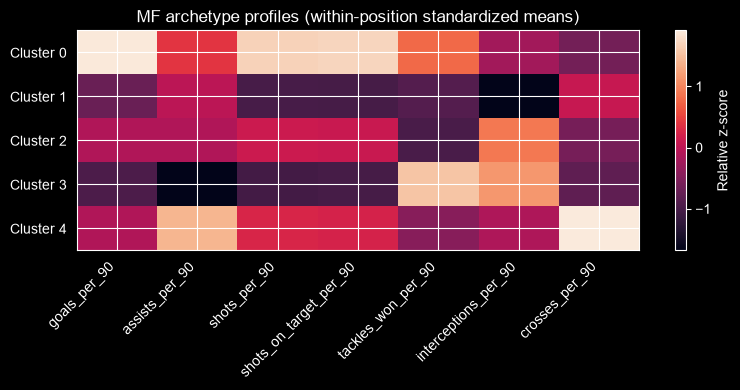

In [9]:
cluster_profile = (
    clustered.groupby(["position_group", "cluster"])[usable_features]
    .mean()
    .round(3)
    .reset_index()
)

cluster_sizes = (
    clustered.groupby(["position_group", "cluster"])
    .agg(
        player_season_rows=("player_name", "size"),
        unique_players=("player_name", "nunique"),
        median_minutes=("minutes", "median")
    )
    .reset_index()
)

display(cluster_sizes)
display(cluster_profile)

# Standardized feature heatmaps help describe relative cluster profiles.
for position in clustered["position_group"].unique():
    prof = cluster_profile[cluster_profile["position_group"] == position].set_index("cluster")[usable_features]
    if prof.empty:
        continue

    # For display only: z-score each feature across the clusters in this position.
    prof_z = (prof - prof.mean()) / prof.std(ddof=0).replace(0, np.nan)
    fig, ax = plt.subplots(figsize=(max(8, len(usable_features) * 0.8), 4))
    image = ax.imshow(prof_z.fillna(0).values, aspect="auto")
    ax.set_xticks(range(len(usable_features)))
    ax.set_xticklabels(usable_features, rotation=45, ha="right")
    ax.set_yticks(range(len(prof_z.index)))
    ax.set_yticklabels([f"Cluster {i}" for i in prof_z.index])
    ax.set_title(f"{position} archetype profiles (within-position standardized means)")
    fig.colorbar(image, ax=ax, label="Relative z-score")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"ml_cluster_profile_{position.lower()}.png", dpi=160)
    plt.show()


## 7. Find similar player-season profiles

In [10]:
# Similarity is computed within the same position group on the same feature set.
# The selected reference player must have a row in the clustered sample.
REFERENCE_PLAYER = None  # e.g. "Vinícius Júnior"; leave None to inspect available names first.

available_names = sorted(clustered["player_name"].dropna().unique().tolist())
print("Players available for similarity search:")
print(available_names)

if REFERENCE_PLAYER is not None:
    reference_rows = clustered[clustered["player_name"].str.casefold() == REFERENCE_PLAYER.casefold()]
    if reference_rows.empty:
        raise ValueError(f"{REFERENCE_PLAYER} is not in the clustered sample.")
    reference = reference_rows.sort_values("season").iloc[-1]
    peer_group = clustered[
        (clustered["position_group"] == reference["position_group"])
        & (clustered["player_name"] != reference["player_name"])
    ].copy()

    prep = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    peer_matrix = prep.fit_transform(peer_group[usable_features])
    ref_matrix = prep.transform(reference[usable_features].to_frame().T)
    peer_group["cosine_similarity"] = cosine_similarity(ref_matrix, peer_matrix).ravel()
    similar_players = peer_group.sort_values("cosine_similarity", ascending=False).head(10)

    display(similar_players[[
        "player_name", "season", "position_group", "minutes",
        "cluster", "cosine_similarity"
    ]])
else:
    print("Set REFERENCE_PLAYER to a player name and rerun this cell to calculate similar profiles.")


Players available for similarity search:
['Antonio Rüdiger', 'Arda Güler', 'Aurélien Tchouaméni', 'Brahim Díaz', 'Dani Carvajal', 'Dani Ceballos', 'David Alaba', 'Dean Huijsen', 'Eduardo Camavinga', 'Federico Valverde', 'Ferland Mendy', 'Fran Garcia', 'Franco Mastantuono', 'Gonzalo García', 'Joselu', 'Jude Bellingham', 'Kylian Mbappé', 'Lucas Vázquez', 'Luka Modrić', 'Nacho', 'Raúl Asencio', 'Rodrygo', 'Thiago Pinar', 'Toni Kroos', 'Trent Alexander-Arnold', 'Vinicius Júnior', 'Álvaro Carreras', 'Éder Militão']
Set REFERENCE_PLAYER to a player name and rerun this cell to calculate similar profiles.


## 8. Export ML outputs and model metadata

In [11]:
cluster_path = DATA_DIR / "real_madrid_player_archetypes.csv"
profile_path = REPORTS_DIR / "ml_cluster_profiles.csv"
evaluation_path = REPORTS_DIR / "ml_cluster_evaluation.csv"
metadata_path = MODELS_DIR / "player_archetype_model_metadata.json"

clustered.to_csv(cluster_path, index=False)
cluster_profile.to_csv(profile_path, index=False)
cluster_evaluation.to_csv(evaluation_path, index=False)

metadata = {
    "model": "KMeans",
    "task": "Unsupervised player archetype discovery",
    "random_state": 42,
    "input_file": str(INPUT_PATH),
    "features": usable_features,
    "position_groups": sorted(clustered["position_group"].unique().tolist()),
    "minimum_minutes": MIN_MINUTES_FOR_CLUSTERING,
    "selection_metric": "Silhouette score",
    "cluster_evaluation": cluster_evaluation.to_dict(orient="records"),
    "limitations": [
        "Only Real Madrid player-season rows are included; this is not an external transfer market model.",
        "Three seasons and one club provide a small, selection-biased sample.",
        "Clusters describe statistical similarity, not quality or future potential.",
        "Per-90 metrics can be volatile even after a minimum-minutes threshold.",
        "Median imputation and scaling affect the cluster structure.",
        "Similarity is meaningful only within the same broad position group."
    ]
}
metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

print("Saved:", cluster_path)
print("Saved:", profile_path)
print("Saved:", evaluation_path)
print("Saved:", metadata_path)


Saved: C:\Users\1alma\DataspellProjects\real-madrid-ai\data\processed\real_madrid_player_archetypes.csv
Saved: C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\ml_cluster_profiles.csv
Saved: C:\Users\1alma\DataspellProjects\real-madrid-ai\reports\ml_cluster_evaluation.csv
Saved: C:\Users\1alma\DataspellProjects\real-madrid-ai\models\player_archetype_model_metadata.json
